In [23]:
%load_ext autoreload
%autoreload 2

import sys, os, time
PROJECT_ROOT = os.path.abspath("..")
SRC_ROOT = os.path.join(PROJECT_ROOT, "src")
if SRC_ROOT not in sys.path:
    sys.path.insert(0, SRC_ROOT)

import golconda
from golconda import *          # WaveletDecomposer, PowerSpectrum, adjust_map_l1, …

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
from matplotlib.ticker import ScalarFormatter
from skimage.transform import downscale_local_mean
from scipy.interpolate import CubicSpline
import math

plt.rcParams.update({
    'axes.titlesize': 12, 'axes.labelsize': 12,
    'legend.fontsize': 12, 'xtick.labelsize': 12, 'ytick.labelsize': 12,
    'axes.linewidth': 2., 'lines.linewidth': 3.0, 'lines.markersize': 3,
})
print(f"golconda {golconda.__version__} — imports OK")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Imports OK


## Load simulation data and extract target statistics

In [47]:
path     = '../../data/2.007kappa_weight.dat_LOS400'
angle    = 10          # field of view in degrees
N        = 256         # size of the target patch (extract Cls + l1 stats from here)
output_size = 256      # size of the map to generate  (can differ from N)

loader = SimulationDataLoader(user_defined_angle=angle)
loaded_data, loaded_angle = loader.load_data(path)
data_downscaled = downscale_local_mean(loaded_data - np.mean(loaded_data), (4, 4))

# pixelsize is derived from the *full* downscaled map so it is the same
# physical scale for both the target patch and the output gaussian.
pixelsize = loaded_angle.value * 60 / data_downscaled.shape[0]   # arcmin/pixel
target    = data_downscaled[:N, :N]

print(f"Full downscaled shape : {data_downscaled.shape}")
print(f"Target patch shape    : {target.shape}")
print(f"Output map shape      : ({output_size}, {output_size})")
print(f"Pixel size            : {pixelsize:.4f} arcmin/pixel")

# ── Power spectrum of the target ──────────────────────────────────────────────
pkadjuster_target = PowerSpectrum(target, pixelsize)
_, target_ells, target_cls = pkadjuster_target.calculate_Cls(target)

# ── l1-norm statistics of the target ─────────────────────────────────────────
filter_type = 'tophat'
nscales     = 2
nbins       = [71] * (nscales + 1)
density     = False

decomposer    = WaveletDecomposer()
target_values = process_image(target, filter_type, nscales, nbins, decomposer, density=density)
print(f"\nTarget statistics computed for {nscales} scales.")
print(f"source_pixels stored in target_values: {target_values['scale_0']['source_pixels']}")

Full downscaled shape : (1937, 1937)
Target patch shape    : (256, 256)
Output map shape      : (256, 256)
Pixel size            : 0.3098 arcmin/pixel

Target statistics computed for 2 scales.
source_pixels stored in target_values: 65536


## JAX JIT warm-up

The first call to `decompose` triggers XLA compilation and caches both the
compiled kernel and the pre-computed Bessel filters.  All subsequent calls
with the same map shape reuse the cache at zero extra cost.

In [48]:
seed = 10
np.random.seed(seed)
gaussian = np.random.normal(0., np.std(target), (output_size, output_size))

print("Warming up JIT (first decompose compiles the XLA kernel)...")
t0 = time.perf_counter()
_ = decomposer.decompose(gaussian, num_scales=nscales,
                         filter_type=filter_type, recalculate_params=True)
print(f"  First call (compile + filter cache build): {(time.perf_counter()-t0)*1e3:.0f} ms")

t0 = time.perf_counter()
_ = decomposer.decompose(gaussian, num_scales=nscales,
                         filter_type=filter_type, recalculate_params=False)
print(f"  Second call (cached JIT):                  {(time.perf_counter()-t0)*1e3:.1f} ms")

pkadjuster = PowerSpectrum(gaussian, pixelsize)

Warming up JIT (first decompose compiles the XLA kernel)...
  First call (compile + filter cache build): 8 ms
  Second call (cached JIT):                  1.6 ms


## Emulation loop

Each iteration:
1. **Wavelet decompose** — `lax.scan` over scales, compiled into a single XLA program
2. **Adjust l1-norm** per scale — numpy (coefficient histogram matching)
3. **Adjust power spectrum** — JAX rfft2 / irfft2 with fixed interpolation fill values
4. **Average** l1 and Cls adjusted maps, clip to target range

In [49]:
n_iter   = 1050
solution = gaussian.copy()
total_error = []

t_loop = time.perf_counter()

for it in range(n_iter):
    # ── decompose (recalculate_params=False: reuse cached grid & JIT) ────────
    t_dec = time.perf_counter()
    solution_coefs = decomposer.decompose(
        solution, num_scales=nscales,
        filter_type=filter_type, recalculate_params=False,
    )
    t_dec = time.perf_counter() - t_dec

    # ── adjust l1-norm per scale ─────────────────────────────────────────────
    error_per_scale = 0.
    for scale in range(nscales + 1):
        solution_coefs[scale], err = adjust_map_l1(
            solution_coefs[scale], mask=None,
            targetvalues=target_values[f'scale_{scale}'],
            density=density,
        )
        error_per_scale += err
    total_error.append(error_per_scale)
    solution_l1 = np.sum(solution_coefs, axis=0)

    # ── adjust power spectrum ─────────────────────────────────────────────────
    solution_cl = pkadjuster.generate_field_with_target_cls(
        solution, target_cls, target_ells,
    )

    # ── combine and clip ──────────────────────────────────────────────────────
    solution = np.clip(
        0.5 * (solution_cl + solution_l1),
        np.min(target), np.max(target),
    )

    print(f"\r  iter {it+1:3d}/{n_iter}  |  decompose {t_dec*1e3:5.1f} ms  |  "
          f"l1 error {error_per_scale*100:.2f}%", end="", flush=True)

total_time = time.perf_counter() - t_loop
print(f"\n\nTotal loop time : {total_time:.1f} s  ({total_time/n_iter*1e3:.0f} ms/iter)")

  iter 1050/1050  |  decompose   0.9 ms  |  l1 error 1.19%

Total loop time : 27.2 s  (26 ms/iter)


## Convergence

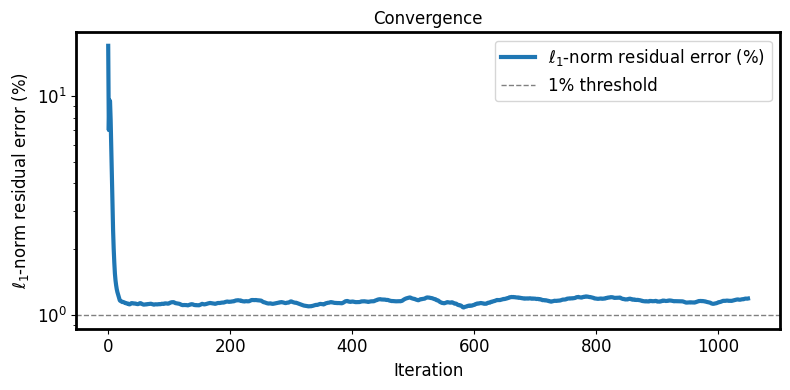

In [50]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.array(total_error) * 100, label=r"$\ell_1$-norm residual error (%)")
ax.axhline(1, color='grey', ls='--', lw=1, label="1% threshold")
ax.set_yscale('log')
ax.set_xlabel("Iteration")
ax.set_ylabel(r"$\ell_1$-norm residual error (%)")
ax.set_title("Convergence")
ax.legend()
plt.tight_layout()
plt.show()

## Map comparison

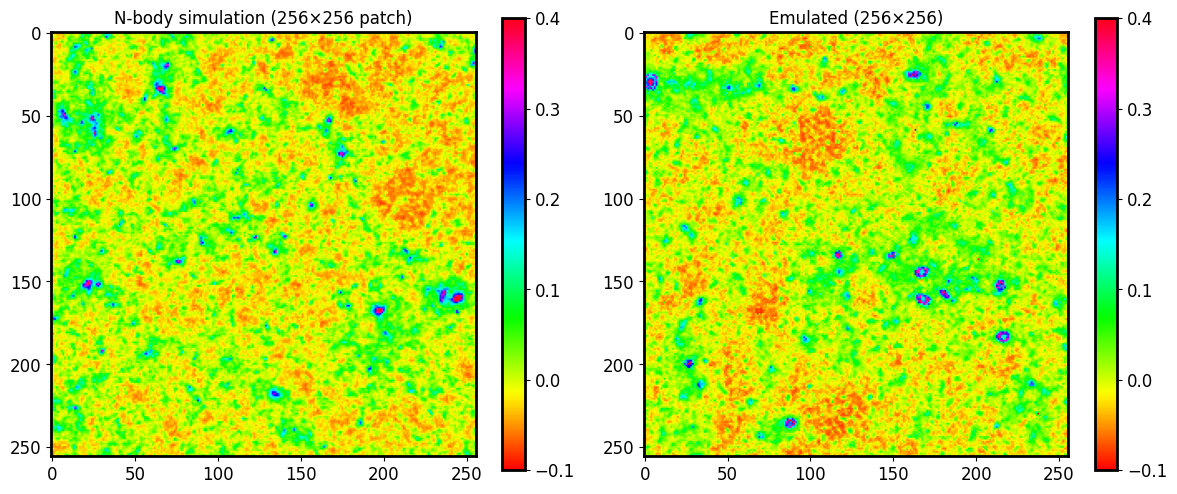

In [51]:
vmin, vmax, cmap = -0.1, 0.4, 'hsv'
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(target[:output_size, :output_size], vmin=vmin, vmax=vmax, cmap=cmap)
axes[0].set_title(f'N-body simulation ({output_size}×{output_size} patch)')
plt.colorbar(axes[0].images[0], ax=axes[0])
axes[1].imshow(solution, vmin=vmin, vmax=vmax, cmap=cmap)
axes[1].set_title(f'Emulated ({output_size}×{output_size})')
plt.colorbar(axes[1].images[0], ax=axes[1])
plt.tight_layout()
plt.show()

## Power spectrum

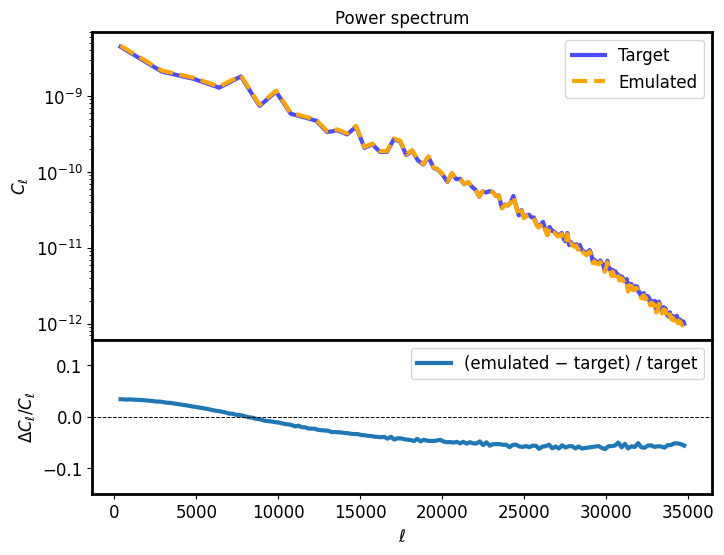

In [52]:
_, sol_ells, sol_cls = pkadjuster.calculate_Cls(solution)

gs = GridSpec(2, 1, height_ratios=[2, 1], hspace=0)
fig = plt.figure(figsize=(8, 6))

ax0 = fig.add_subplot(gs[0])
ax0.loglog(target_ells[1:], target_cls[1:], label='Target', lw=3, c='blue', alpha=0.7)
ax0.loglog(sol_ells[1:],    sol_cls[1:],    label='Emulated', c='orange', ls='--', lw=3)
ax0.set_ylabel(r'$C_\ell$')
ax0.set_title('Power spectrum')
ax0.legend()
ax0.tick_params(labelbottom=False)

ax1 = fig.add_subplot(gs[1])
spl = CubicSpline(sol_ells, sol_cls)
valid = (target_ells >= sol_ells[0]) & (target_ells <= sol_ells[-1])
ax1.plot(target_ells[valid],
         (spl(target_ells[valid]) - target_cls[valid]) / target_cls[valid],
         label='(emulated − target) / target')
ax1.axhline(0, color='k', lw=0.7, ls='--')
ax1.set_ylim(-0.15, 0.15)
ax1.set_xlabel(r'$\ell$')
ax1.set_ylabel(r'$\Delta C_\ell / C_\ell$')
ax1.legend()
plt.show()

## ℓ₁-norm per wavelet scale

/var/folders/4z/j812r6_x1b33_hsc69yh9m240000gp/T/ipykernel_99246/2747187985.py:45: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


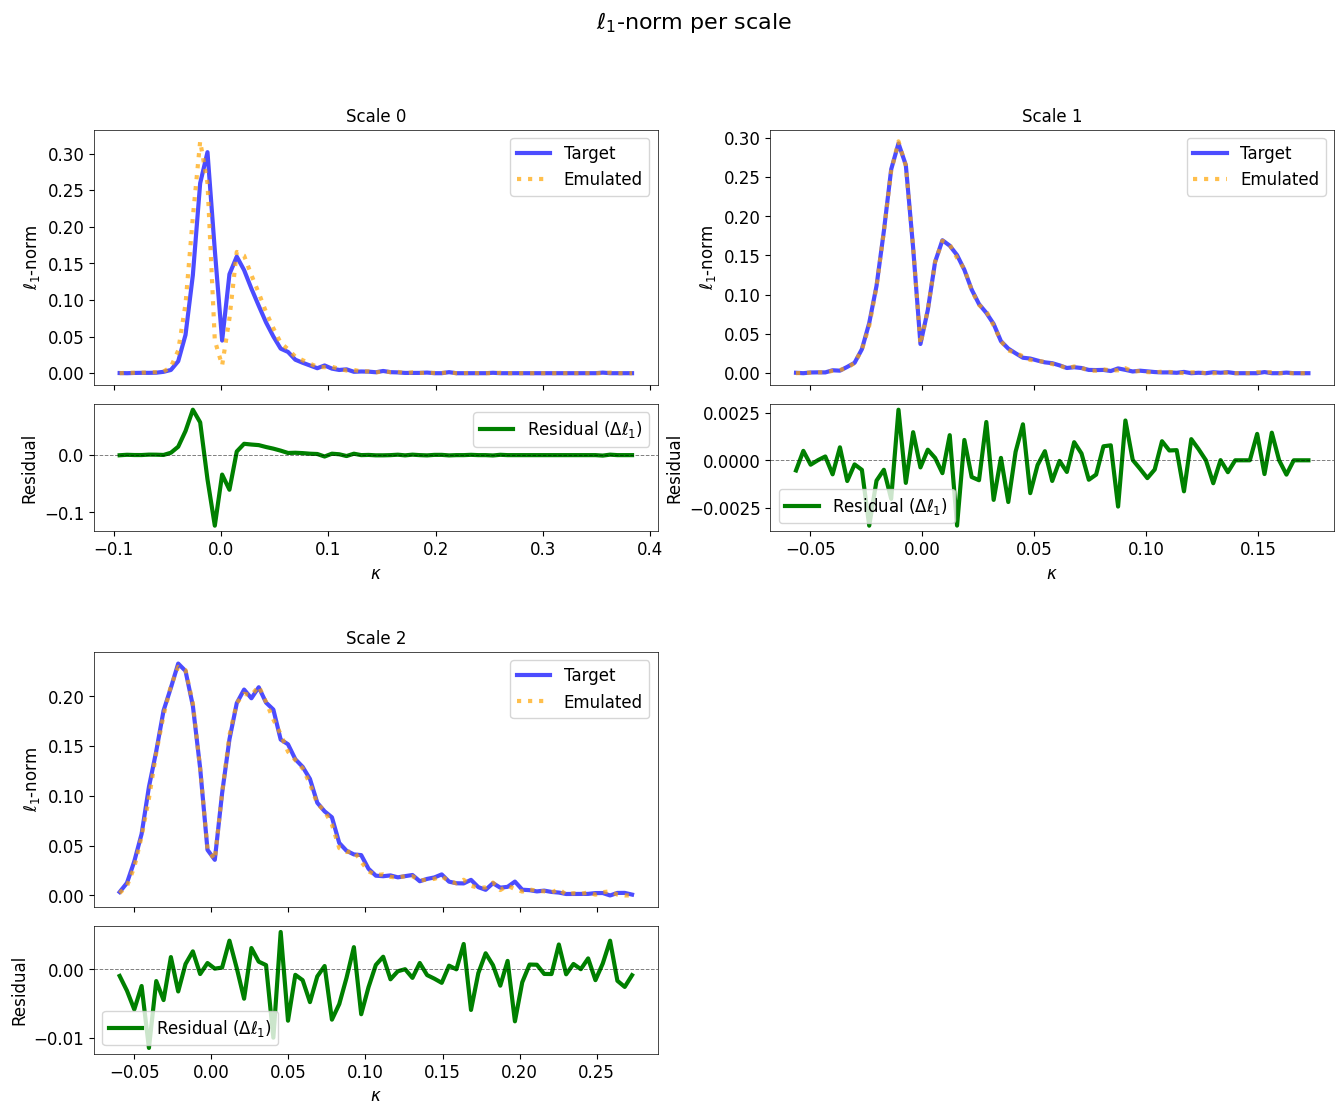

In [53]:
solution_coefs = decomposer.decompose(
    solution, num_scales=nscales,
    filter_type=filter_type, recalculate_params=False,
)

ncols = math.ceil((nscales + 1) / 2)
fig = plt.figure(figsize=(8 * ncols, 12))
outer = GridSpec(2, ncols, height_ratios=[1, 1], hspace=0.3)

for scale in range(nscales + 1):
    row, col = divmod(scale, ncols)
    inner = GridSpecFromSubplotSpec(
        2, 1, subplot_spec=outer[row, col], height_ratios=[2, 1], hspace=0.1,
    )
    ax_m = fig.add_subplot(inner[0])
    ax_r = fig.add_subplot(inner[1], sharex=ax_m)

    edges_t   = target_values[f'scale_{scale}']['binedges']
    centers_t = target_values[f'scale_{scale}']['bincenters']
    l1_t      = target_values[f'scale_{scale}']['l1_norm']

    _, centers_s, _, l1_s = calculate_histogram_l1norm(
        solution_coefs[scale], mask=None, nbins=edges_t, density=density,
    )

    ax_m.plot(centers_t, l1_t, label='Target',  color='blue',   alpha=0.7)
    ax_m.plot(centers_s, l1_s, label='Emulated', color='orange', alpha=0.7, ls=':')
    ax_m.set_title(f'Scale {scale}')
    ax_m.set_ylabel(r'$\ell_1$-norm')
    ax_m.legend()
    ax_m.tick_params(labelbottom=False)

    ax_r.plot(centers_t, l1_s - l1_t, color='green',
              label=r'Residual ($\Delta\ell_1$)')
    ax_r.axhline(0, color='k', ls='--', lw=0.7, alpha=0.5)
    ax_r.set_xlabel(r'$\kappa$')
    ax_r.set_ylabel('Residual')
    ax_r.legend()

for ax in fig.axes:
    for sp in ax.spines.values():
        sp.set_linewidth(0.5)

plt.suptitle(r"$\ell_1$-norm per scale", fontsize=16)
plt.tight_layout()
plt.show()

## Pixel-value histogram (full map)

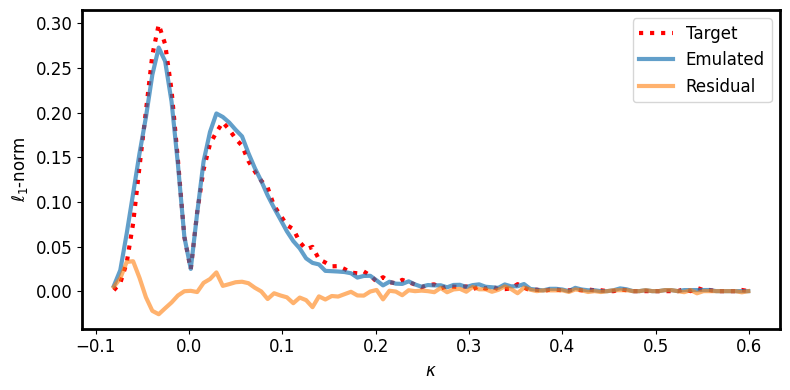

In [54]:
edges_t, centers_t, _, l1_t = calculate_histogram_l1norm(
    target, mask=None, nbins=100, density=density,
)
_, centers_s, _, l1_s = calculate_histogram_l1norm(
    solution, mask=None, nbins=edges_t, density=density,
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(centers_t, l1_t, label='Target',   ls=':',  c='r')
ax.plot(centers_s, l1_s, label='Emulated', alpha=0.7)
ax.plot(centers_t, l1_s - l1_t, label='Residual', alpha=0.6)
ax.set_xlabel(r'$\kappa$')
ax.set_ylabel(r'$\ell_1$-norm')
ax.legend()
plt.tight_layout()
plt.show()